# Reproducibility, Replicability, and Generalizability in Digital Marketing Analytics

Companion notebook for my Marketing Data Science article of the same name.

In this notebook, I take one simple marketing model and run it through three tests:

1. Reproducibility. If I rerun the analysis with the same data and code, do I get the same answer? Repeatability, getting my own answer again, is the starting point.
2. Replicability. If I collect new data from the same process, does the finding show up again?
3. Generalizability. If conditions change, does the finding still hold?

At the end, I look at one more issue. A result can pass all three tests and still be wrong.

## The example

A small business wants to know how its marketing spend affects weekly sales. It spends money in three channels: paid search, social, and email. I use ordinary least squares (OLS) regression to estimate the effect of each channel.

## Why simulated data?

I generated the data myself, so I know the true effect of each channel. That lets me check every result against the right answer. With real business data, we never get to know the true values.

All money amounts are in thousands of dollars. A coefficient of 2.0 on paid search means that each additional 1,000 dollars of weekly search spend adds about 2,000 dollars in weekly sales.

## Setup

In [1]:
import hashlib
import os
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import statsmodels
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Record the environment. This is the cheapest reproducibility habit there is.
print("Python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("statsmodels ", statsmodels.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)

os.makedirs("figures", exist_ok=True)
pd.set_option("display.precision", 3)

Python       3.13.16
numpy        2.1.3
pandas       2.2.3
statsmodels  0.15.0
scikit-learn 1.6.1
matplotlib   3.10.0


In [2]:
# Figure style: clean, white background, thin marks, recessive axes.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": MUTED,
    "axes.edgecolor": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "legend.frameon": False,
    "lines.linewidth": 2,
})

def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")

## How the data is generated

Every dataset in this notebook comes from the same set of rules. Weekly sales depend on:

- Paid search, with a true effect of 2.0
- Social, with a true effect of 1.2
- Email, with a true effect of 3.0
- Seasonality, a yearly cycle that peaks during the holidays
- Random noise, which covers everything else that moves sales from week to week

There is one detail that becomes important later. The business spends more on paid search during its busy season, so search spend and seasonality rise and fall together. Many businesses do this, and it can cause problems when the model is not set up correctly.

In [3]:
TRUE_EFFECTS = {"search": 2.0, "social": 1.2, "email": 3.0}
FEATURES = ["search", "social", "email", "season"]


def simulate_weeks(n_weeks=156, seed=None, start_week=0, search_effect=None):
    # One business, weekly data. Money in $K.
    #   seed:          random seed; None means "unseeded" (different every run)
    #   start_week:    lets us simulate later periods that continue the calendar
    #   search_effect: optional function of week number that changes the true
    #                  search effect, used to simulate a market shift
    rng = np.random.default_rng(seed)
    week = np.arange(start_week, start_week + n_weeks)

    # Seasonality peaks around week 47 (late November).
    season = np.cos(2 * np.pi * ((week % 52) - 47) / 52)

    # Spend decisions. Search spend rises in the busy season.
    search = np.clip(20 + 5 * season + rng.normal(0, 6, n_weeks), 2, None)
    social = np.clip(12 + rng.normal(0, 4, n_weeks), 1, None)
    email = np.clip(5 + rng.normal(0, 2.5, n_weeks), 0.5, None)

    if search_effect is None:
        b_search = np.full(n_weeks, TRUE_EFFECTS["search"])
    else:
        b_search = search_effect(week)

    sales = (
        100
        + b_search * search
        + TRUE_EFFECTS["social"] * social
        + TRUE_EFFECTS["email"] * email
        + 30 * season
        + rng.normal(0, 12, n_weeks)
    )
    # Online orders: roughly 4 orders per $1K of sales. Only known once the week is over.
    orders = 4 * sales + rng.normal(0, 25, n_weeks)
    return pd.DataFrame({"week": week, "search": search, "social": social,
                         "email": email, "season": season, "sales": sales,
                         "orders": orders})


def fit_ols(df, features=FEATURES):
    X = sm.add_constant(df[features])
    return sm.OLS(df["sales"], X).fit()


SEED = 2026
data = simulate_weeks(seed=SEED)          # three years of weekly data
data.head()

,week,search,social,email,season,sales,orders
0,0,19.356,10.186,2.678,0.823,167.135,633.905
1,1,25.186,2.988,4.799,0.749,192.287,755.059
2,2,11.938,13.987,5.498,0.663,189.860,759.959
3,3,31.215,14.970,3.167,0.568,208.632,819.865
4,4,26.153,14.485,2.727,0.465,193.602,787.885


In [4]:
model = fit_ols(data)
print(model.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        102.1710      4.778     21.386      0.000      92.731     111.611
search         1.7652      0.158     11.190      0.000       1.454       2.077
social         1.2611      0.239      5.285      0.000       0.790       1.733
email          3.5007      0.411      8.512      0.000       2.688       4.313
season        34.5478      1.642     21.040      0.000      31.303      37.792


With three years of data and the correct model, the estimates come out close to the true values of 2.0, 1.2, and 3.0. This is the baseline for the rest of the notebook.

# Part 1. Reproducibility

If I rerun this analysis, or someone else runs it from my files, will we get the same answer?

## 1a. Repeatability

Anything random in an analysis will change from run to run unless the random seed is fixed. That includes simulated data, train/test splits, bootstrapping, and some model fitting methods. Below, I run the full analysis five times without a seed and five times with a seed.

In [5]:
def search_estimate(seed):
    return fit_ols(simulate_weeks(seed=seed)).params["search"]

unseeded = [search_estimate(None) for _ in range(5)]
seeded = [search_estimate(SEED) for _ in range(5)]

repeat_df = pd.DataFrame({"run": range(1, 6),
                          "unseeded": unseeded,
                          "seeded (seed=2026)": seeded})
print(repeat_df.round(4).to_string(index=False))
print(f"\nUnseeded runs spread: {max(unseeded) - min(unseeded):.3f}")
print(f"Seeded runs spread:   {max(seeded) - min(seeded):.3f}")

 run  unseeded  seeded (seed=2026)
   1     2.063               1.765
   2     2.106               1.765
   3     2.056               1.765
   4     1.811               1.765
   5     1.917               1.765

Unseeded runs spread: 0.294
Seeded runs spread:   0.000


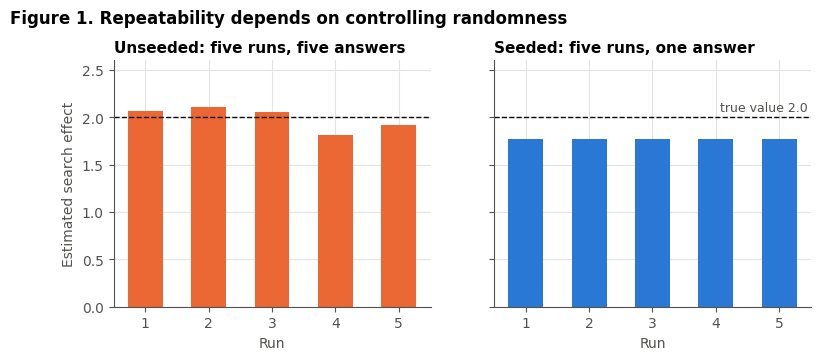

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, vals, title, color in [
    (axes[0], unseeded, "Unseeded: five runs, five answers", ORANGE),
    (axes[1], seeded, "Seeded: five runs, one answer", BLUE),
]:
    ax.bar(range(1, 6), vals, color=color, width=0.55)
    ax.axhline(TRUE_EFFECTS["search"], color=INK, lw=1, ls="--")
    ax.set_title(title)
    ax.set_xlabel("Run")
    ax.set_xticks(range(1, 6))
axes[0].set_ylabel("Estimated search effect")
axes[1].text(5.45, TRUE_EFFECTS["search"] + 0.06, "true value 2.0", ha="right", color=MUTED, fontsize=9)
axes[0].set_ylim(0, 2.6)
fig.suptitle("Figure 1. Repeatability depends on controlling randomness", x=0.01, ha="left",
             fontweight="bold", y=1.04)
save(fig, "fig1_repeatability")
plt.show()

None of the unseeded runs are wrong. Each one is a reasonable estimate. The problem is consistency. If I report one number on Monday and a different number on Friday, and I cannot explain why, it is hard for anyone to trust either one. On the podcast that inspired this article, Bernadette Boscoe says she tells her students that reproducibility is for their future selves, because they will not remember what they did.

## 1b. Reproducibility

Two simple habits make it possible for someone else to check this analysis:

1. Record the environment. The first code cell prints the Python and package versions, and the GitHub repository includes a requirements.txt file.
2. Fingerprint the results. I create a short hash of the data and of the coefficient table. If someone else gets the same hash, they have the same numbers without having to compare them line by line.

In [7]:
def fingerprint(obj, decimals=6):
    # Short SHA-256 hash of a DataFrame or Series, rounded to a stated precision.
    if isinstance(obj, pd.Series):
        obj = obj.to_frame()
    text = obj.round(decimals).to_csv(index=True)
    return hashlib.sha256(text.encode()).hexdigest()[:12]

print("Data fingerprint:        ", fingerprint(data))
print("Coefficient fingerprint: ", fingerprint(model.params))

Data fingerprint:         f5bd1598c81c
Coefficient fingerprint:  6d368e34b4e9


I round the numbers before creating the hash. Different computers can disagree in the 15th decimal place because of the way they handle floating-point math. Boscoe made a similar point on the podcast. Getting an exact match on a different setup is often not realistic, so the practical goal is to get results within an acceptable range. Here I use six decimal places, which is far more precise than any marketing decision requires.

## 1c. Comparing software packages

Another way to check an analysis is to fit the same model with different tools. Below, I fit the regression with statsmodels, scikit-learn, and NumPy.

In [8]:
X = data[FEATURES]
y = data["sales"]

sk = LinearRegression().fit(X, y)
Xn = np.column_stack([np.ones(len(X)), X.values])
np_coef, *_ = np.linalg.lstsq(Xn, y.values, rcond=None)

compare = pd.DataFrame({
    "statsmodels": model.params.values,
    "scikit-learn": np.r_[sk.intercept_, sk.coef_],
    "numpy lstsq": np_coef,
}, index=["intercept"] + FEATURES)
print(compare.round(6))

max_gap = (compare.max(axis=1) - compare.min(axis=1)).max()
print(f"\nLargest disagreement between tools: {max_gap:.2e}")
print("Agree within 1e-8:", np.allclose(compare["statsmodels"], compare["scikit-learn"], atol=1e-8)
      and np.allclose(compare["statsmodels"], compare["numpy lstsq"], atol=1e-8))

           statsmodels  scikit-learn  numpy lstsq
intercept      102.171       102.171      102.171
search           1.765         1.765        1.765
social           1.261         1.261        1.261
email            3.501         3.501        3.501
season          34.548        34.548       34.548

Largest disagreement between tools: 1.28e-13
Agree within 1e-8: True


All three packages produce the same coefficients. For a linear regression, I expected that. The check is still worth doing because it takes very little time. It becomes more useful with models that are fit using iterative or random methods.

# Part 2. Replicability

If I use new data from the same process, does the finding show up again?

## 2a. The lucky split

Before collecting new data, there is a simpler check. Most analyses set aside some of the data to test the model. With a small dataset, the weeks that end up in the test set can make a big difference in the score. Below, I use 18 months of data and draw the test set 20 different ways.

In [9]:
short = simulate_weeks(n_weeks=78, seed=SEED)   # 18 months
TEST_WEEKS = 16

rows = []
for split_seed in range(20):
    order = np.random.default_rng(split_seed).permutation(len(short))
    test, train = short.iloc[order[:TEST_WEEKS]], short.iloc[order[TEST_WEEKS:]]
    m = LinearRegression().fit(train[FEATURES], train["sales"])
    rows.append({"split": split_seed,
                 "test_MAE": mean_absolute_error(test["sales"], m.predict(test[FEATURES])),
                 "search_effect": m.coef_[0]})
splits = pd.DataFrame(rows)

lucky = splits.loc[splits["test_MAE"].idxmin()]
print(f"Best single split:  MAE = {lucky.test_MAE:.1f}  (split {int(lucky.split)})")
print(f"Median of 20 splits: MAE = {splits.test_MAE.median():.1f}")
print(f"Range:               {splits.test_MAE.min():.1f} to {splits.test_MAE.max():.1f}")

Best single split:  MAE = 6.4  (split 2)
Median of 20 splits: MAE = 9.9
Range:               6.4 to 13.5


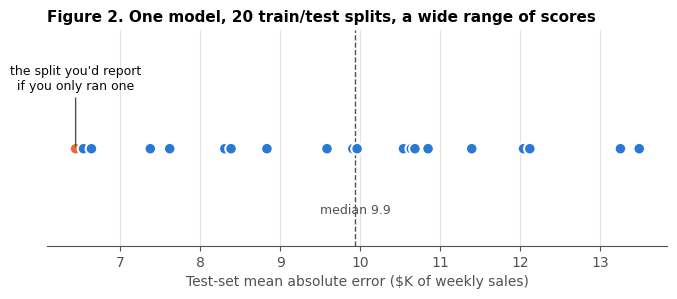

In [10]:
fig, ax = plt.subplots(figsize=(8, 2.8))
s = splits.sort_values("test_MAE").reset_index(drop=True)
colors = [ORANGE if i == 0 else BLUE for i in range(len(s))]
ax.scatter(s["test_MAE"], np.zeros(len(s)), s=70, c=colors, edgecolor="white", linewidth=1.5, zorder=3)
ax.axvline(s["test_MAE"].median(), color=MUTED, lw=1, ls="--")
ax.annotate("the split you'd report\nif you only ran one", (s.test_MAE[0], 0), xytext=(s.test_MAE[0], 0.55),
            ha="center", color=INK, fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.text(s.test_MAE.median(), -0.6, f"median {s.test_MAE.median():.1f}", ha="center", color=MUTED, fontsize=9)
ax.set_yticks([])
ax.set_ylim(-0.9, 1.1)
ax.spines["left"].set_visible(False)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Test-set mean absolute error ($K of weekly sales)")
ax.set_title("Figure 2. One model, 20 train/test splits, a wide range of scores")
save(fig, "fig2_lucky_split")
plt.show()

The model and the data stayed the same. The only thing that changed was which weeks ended up in the test set. If I had run a single split and happened to get the best one, I would have reported an error that was only about two-thirds of the typical result. Looking at the range across many splits, or using cross-validation, gives a more accurate picture.

## 2b. Replication with new data

Next, I simulate five new three-year datasets from the same process. You can think of these as five similar businesses running the same analysis. I want to see whether the search effect shows up again. To get a better sense of the pattern, I then repeat the process 200 times.

In [11]:
def estimate_with_ci(df, features):
    fit = fit_ols(df, features)
    lo, hi = fit.conf_int().loc["search"]
    return fit.params["search"], lo, hi

studies = {"Original": data}
for i in range(1, 6):
    studies[f"Replication {i}"] = simulate_weeks(seed=SEED + i)

rep_rows = []
for name, df in studies.items():
    est, lo, hi = estimate_with_ci(df, FEATURES)
    rep_rows.append({"study": name, "estimate": est, "ci_low": lo, "ci_high": hi,
                     "covers_truth": lo <= TRUE_EFFECTS["search"] <= hi})
replication = pd.DataFrame(rep_rows)
print(replication.round(2).to_string(index=False))

# 200 replications: how often does the 95% interval contain the truth?
many = pd.DataFrame([estimate_with_ci(simulate_weeks(seed=10_000 + i), FEATURES) for i in range(200)],
                    columns=["estimate", "ci_low", "ci_high"])
coverage = ((many.ci_low <= TRUE_EFFECTS["search"]) & (TRUE_EFFECTS["search"] <= many.ci_high)).mean()
print(f"\nAcross 200 replications: mean estimate {many.estimate.mean():.2f}, "
      f"middle 90% of estimates {many.estimate.quantile(.05):.2f} to {many.estimate.quantile(.95):.2f}, "
      f"intervals covering 2.0: {coverage:.0%}")

        study  estimate  ci_low  ci_high  covers_truth
     Original      1.77    1.45     2.08          True
Replication 1      2.00    1.70     2.30          True
Replication 2      1.98    1.66     2.31          True
Replication 3      1.99    1.68     2.29          True
Replication 4      2.18    1.85     2.50          True
Replication 5      1.95    1.67     2.23          True

Across 200 replications: mean estimate 2.01, middle 90% of estimates 1.73 to 2.25, intervals covering 2.0: 96%


The estimates vary from one dataset to the next, and some confidence intervals miss the true value. That is expected. A 95% confidence interval should miss the true value about 5% of the time, and that is close to what happened across the 200 replications. The search effect keeps coming back close to 2.0, so the finding replicates. Replication means getting consistent results, not identical results.

# Part 3. Generalizability

Does the result still hold in a different time period, market, or set of conditions?

## 3a. A change in the market

Suppose that at week 130, about halfway through the third year, a new competitor starts bidding on the same search terms. From that point on, each dollar of search spend produces half as much in sales. The model has no information about this change.

I test the same model two ways:

- Random split. The test weeks are chosen at random from all three years. Many tutorials use this approach.
- Forward split. The model is trained on the weeks before week 130 and tested on the weeks after it. This matches how the model would be used in practice, with past data used to predict the future.

In [12]:
SHIFT_WEEK = 130
shifted = simulate_weeks(seed=SEED,
                         search_effect=lambda w: np.where(w >= SHIFT_WEEK, 1.0, 2.0))

# Random split
order = np.random.default_rng(0).permutation(len(shifted))
r_test, r_train = shifted.iloc[order[:26]], shifted.iloc[order[26:]]
m_random = LinearRegression().fit(r_train[FEATURES], r_train["sales"])
mae_random = mean_absolute_error(r_test["sales"], m_random.predict(r_test[FEATURES]))

# Forward (time-based) split
f_train, f_test = shifted[shifted.week < SHIFT_WEEK], shifted[shifted.week >= SHIFT_WEEK]
m_forward = LinearRegression().fit(f_train[FEATURES], f_train["sales"])
pred_forward = m_forward.predict(f_test[FEATURES])
mae_forward = mean_absolute_error(f_test["sales"], pred_forward)

print(f"Random split MAE:  {mae_random:.1f}")
print(f"Forward split MAE: {mae_forward:.1f}")
print(f"Average overprediction after the shift: {np.mean(pred_forward - f_test['sales']):.1f} per week")

Random split MAE:  12.5
Forward split MAE: 21.9
Average overprediction after the shift: 20.2 per week


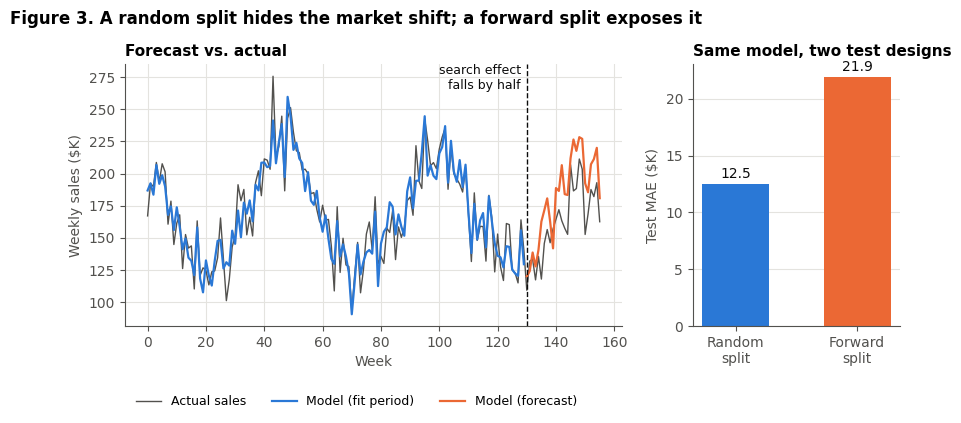

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2.4, 1]})

all_pred = m_forward.predict(shifted[FEATURES])
ax1.plot(shifted.week, shifted.sales, color=MUTED, lw=1, label="Actual sales")
ax1.plot(shifted.week[shifted.week < SHIFT_WEEK], all_pred[shifted.week < SHIFT_WEEK],
         color=BLUE, lw=1.6, label="Model (fit period)")
ax1.plot(f_test.week, pred_forward, color=ORANGE, lw=1.6, label="Model (forecast)")
ax1.axvline(SHIFT_WEEK, color=INK, lw=1, ls="--")
ax1.text(SHIFT_WEEK - 2, 285, "search effect\nfalls by half", ha="right",
         va="top", fontsize=9, color=INK)
ax1.set_xlabel("Week")
ax1.set_ylabel("Weekly sales ($K)")
ax1.legend(loc="upper left", bbox_to_anchor=(0, -0.22), fontsize=9, ncol=3)
ax1.set_title("Forecast vs. actual")

bars = ax2.bar(["Random\nsplit", "Forward\nsplit"], [mae_random, mae_forward],
               color=[BLUE, ORANGE], width=0.55)
for b, v in zip(bars, [mae_random, mae_forward]):
    ax2.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}", ha="center", color=INK, fontsize=10)
ax2.set_ylabel("Test MAE ($K)")
ax2.set_title("Same model, two test designs")
ax2.grid(axis="x", visible=False)

fig.suptitle("Figure 3. A random split hides the market shift; a forward split exposes it",
             x=0.01, ha="left", fontweight="bold", y=1.04)
save(fig, "fig3_market_shift")
plt.show()

With the random split, some of the weeks after the change end up in the training data. The model partly adjusts to the change, so the test results look reasonable. The forward split shows what would actually happen. The model continues to expect search results that are no longer there, and it overpredicts sales every week after the change. A business relying on this model would keep spending too much on search.

## 3b. Data leakage

Data leakage happens when a model is trained using information that will not be available when the model is actually used. Here is a common marketing example. Online orders track closely with sales, so adding them as a feature makes the model look very accurate. The problem is that this week's orders are not known until the week is over. By then, a forecast is no longer needed. A version that would work in practice uses last week's orders instead.

In [14]:
leak = data.copy()
leak["orders_last_week"] = leak["orders"].shift(1)   # honest: known at forecast time
leak = leak.dropna().reset_index(drop=True)

train, test = leak[leak.week < 130], leak[leak.week >= 130]
results = {}
for label, extra in [("Spend + seasonality", []),
                     ("+ last week's orders (honest)", ["orders_last_week"]),
                     ("+ this week's orders (leaky)", ["orders"])]:
    feats = FEATURES + extra
    m = LinearRegression().fit(train[feats], train["sales"])
    results[label] = mean_absolute_error(test["sales"], m.predict(test[feats]))

leak_df = pd.Series(results, name="test_MAE").round(1)
print(leak_df.to_string())

Spend + seasonality              9.1
+ last week's orders (honest)    9.4
+ this week's orders (leaky)     4.1


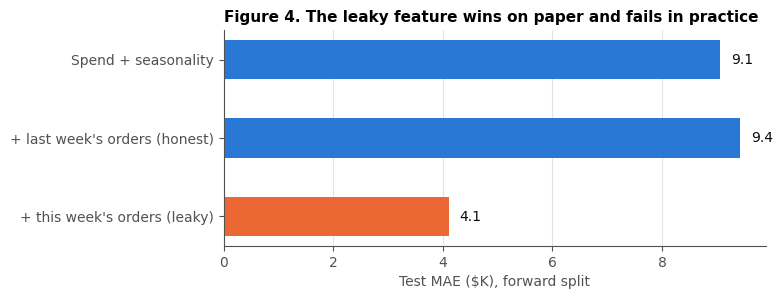

In [15]:
fig, ax = plt.subplots(figsize=(7, 2.8))
labels = list(results.keys())[::-1]
vals = [results[k] for k in labels]
colors = [ORANGE if "leaky" in k else BLUE for k in labels]
bars = ax.barh(labels, vals, color=colors, height=0.5)
for b, v in zip(bars, vals):
    ax.text(v + 0.2, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center", color=INK)
ax.set_xlabel("Test MAE ($K), forward split")
ax.grid(axis="y", visible=False)
ax.set_title("Figure 4. The leaky feature wins on paper and fails in practice")
save(fig, "fig4_leakage")
plt.show()

The model with this week's orders has the lowest error, but it cannot be used for forecasting. This week's orders do not exist yet when the forecast is made. The version with last week's orders performs about the same as the original model. A model with leakage can be reproducible and replicable, but it will not hold up when someone tries to use it.

# Part 4. Reproduced but wrong

Remember that search spend goes up during the busy season. Now suppose an analyst leaves seasonality out of the model. The model has no way to separate the effect of the season from the effect of search, so it gives search credit for sales that the season produced.

Do the three tests catch this mistake? Below, I fit the model without seasonality on the original data and on all five replication datasets.

In [16]:
NO_SEASON = ["search", "social", "email"]

both = []
for name, df in studies.items():
    for label, feats in [("With seasonality", FEATURES), ("Without seasonality", NO_SEASON)]:
        est, lo, hi = estimate_with_ci(df, feats)
        both.append({"study": name, "model": label, "estimate": est, "ci_low": lo, "ci_high": hi})
both = pd.DataFrame(both)

summary = both.pivot(index="study", columns="model", values="estimate").loc[list(studies)]
print(summary.round(2))

wrong = both[both.model == "Without seasonality"]
print(f"\nWithout seasonality, rerunning the original gives the same estimate every time: "
      f"{fingerprint(fit_ols(data, NO_SEASON).params) == fingerprint(fit_ols(data, NO_SEASON).params)}")
print(f"Without seasonality, estimates across six studies: "
      f"{wrong.estimate.min():.2f} to {wrong.estimate.max():.2f} (truth is {TRUE_EFFECTS['search']})")

model          With seasonality  Without seasonality
study                                               
Original                   1.77                 3.46
Replication 1              2.00                 3.13
Replication 2              1.98                 3.48
Replication 3              1.99                 3.51
Replication 4              2.18                 3.46
Replication 5              1.95                 3.28

Without seasonality, rerunning the original gives the same estimate every time: True
Without seasonality, estimates across six studies: 3.13 to 3.51 (truth is 2.0)


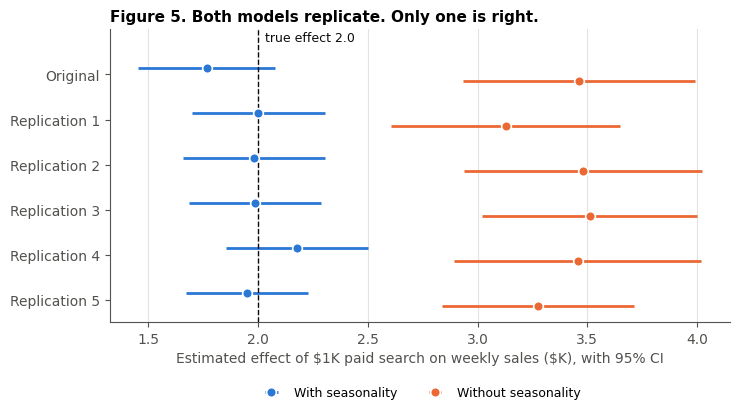

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = list(studies)
y_pos = np.arange(len(names))
for offset, (label, color) in zip([-0.15, 0.15], [("With seasonality", BLUE), ("Without seasonality", ORANGE)]):
    sub = both[both.model == label].set_index("study").loc[names]
    ax.errorbar(sub["estimate"], y_pos + offset,
                xerr=[sub["estimate"] - sub["ci_low"], sub["ci_high"] - sub["estimate"]],
                fmt="o", color=color, ms=7, capsize=0, elinewidth=2, label=label,
                markeredgecolor="white", markeredgewidth=1.2)
ax.axvline(TRUE_EFFECTS["search"], color=INK, lw=1, ls="--")
ax.text(TRUE_EFFECTS["search"] + 0.03, -0.75, "true effect 2.0", ha="left", color=INK, fontsize=9)
ax.set_yticks(y_pos)
ax.set_yticklabels(names)
ax.set_ylim(len(names) - 0.5, -1.0)
ax.set_xlabel("Estimated effect of \\$1K paid search on weekly sales (\\$K), with 95% CI")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=9, ncol=2)
ax.set_title("Figure 5. Both models replicate. Only one is right.")
save(fig, "fig5_replicated_but_wrong")
plt.show()

The model without seasonality reproduces exactly and gives similar results on every dataset. It is also wrong every time, overstating the effect of paid search by more than half. None of its confidence intervals include the true value.

This is the main point I want readers to take away. Reproducibility, replicability, and generalizability tell us whether a result is stable. They do not tell us whether it is correct. A model with a consistent bias will pass every consistency check. To catch a problem like this, we need knowledge of the business (in this case, that search spend follows the season), a better model, or an experiment. One option is to pause search in some weeks or regions and measure what happens to sales.

# Summary

In [18]:
summary_table = pd.DataFrame([
    ["Repeatability", "Seeded vs. unseeded reruns",
     f"Unseeded spread {max(unseeded) - min(unseeded):.2f}; seeded spread 0.00"],
    ["Reproducibility", "Fingerprints and three independent tools",
     f"Tools agree within {max_gap:.0e}"],
    ["Robustness", "20 train/test splits",
     f"MAE ranged {splits.test_MAE.min():.1f} to {splits.test_MAE.max():.1f}"],
    ["Replicability", "200 new datasets",
     f"{coverage:.0%} of 200 intervals cover the true 2.0"],
    ["Generalizability", "Forward split after a market shift",
     f"MAE {mae_random:.1f} (random) vs. {mae_forward:.1f} (forward)"],
    ["Leakage", "This week's vs. last week's orders",
     f"MAE {results['+ this week\'s orders (leaky)']:.1f} (leaky) vs. {results['+ last week\'s orders (honest)']:.1f} (honest)"],
    ["Correctness", "Model without seasonality",
     f"Search effect {wrong.estimate.min():.1f} to {wrong.estimate.max():.1f} vs. true 2.0"],
], columns=["Test", "What we did", "Result"])
print(summary_table.to_string(index=False))

            Test                              What we did                                   Result
   Repeatability               Seeded vs. unseeded reruns Unseeded spread 0.29; seeded spread 0.00
 Reproducibility Fingerprints and three independent tools                 Tools agree within 1e-13
      Robustness                     20 train/test splits                   MAE ranged 6.4 to 13.5
   Replicability                         200 new datasets  96% of 200 intervals cover the true 2.0
Generalizability       Forward split after a market shift     MAE 12.5 (random) vs. 21.9 (forward)
         Leakage       This week's vs. last week's orders         MAE 4.1 (leaky) vs. 9.4 (honest)
     Correctness                Model without seasonality    Search effect 3.1 to 3.5 vs. true 2.0


## Four questions to ask about any marketing number

1. Reproducibility. If someone reran this analysis with the same data and code, would they get the same answer within an acceptable range?
2. Replicability. Has the result shown up again in new data, or only in one train/test split?
3. Generalizability. Was the model tested the way it will be used, such as on a later time period or a different market?
4. Correctness. Is there a reason the result could be consistently wrong, such as a missing factor like seasonality?

## Related articles on Marketing Data Science

- [Introducing the Marketing Analytics Credibility Model (MACM)](https://blog.marketingdatascience.ai/introducing-the-marketing-analytics-credibility-model-macm-0700dea3c08e)
- [The Same Answer, Ten Different Explanations: Non-Determinism in Generative AI Search](https://blog.marketingdatascience.ai/the-same-answer-ten-different-explanations-non-determinism-in-generative-ai-search-e976d5be6e52)
- [How Similar Are AI-Generated Answers?](https://blog.marketingdatascience.ai/how-similar-are-ai-generated-answers-61b74807abfe)